# Evaluation of the Tuned Gradient Boosting Model
This notebook evaluates the single best model identified previously: Gradient Boosting Regressor with tuned hyperparameters.
We will:
- Load data and split into train/val/test (60/20/20).
- Load pipeline.
- Use cross-validation on the training+validation set for robust metrics.
- Fit on train+val, then report metrics on the hold-out test set.
- Visualize Predicted vs Actual (€), Residuals vs Fitted (log), and Top Feature Importances.
- Briefly interpret results and discuss strengths/weaknesses of Gradient Boosting for this problem.

Target is trained on log1p(Price). We also report metrics on the original € scale for interpretability

In [1]:
# 0) Imports & config
import os, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import sqrt

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.ensemble import GradientBoostingRegressor

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (7, 5)
plt.rcParams["axes.grid"] = True
RANDOM_STATE = 42

BASE_PIPE_PATH = "artifacts/melbourne_pipeline.pkl"

# Best params from your model selection step
gb_best_params = dict(
    learning_rate=0.05,
    max_depth=7,
    min_samples_split=5,
    n_estimators=150,
    random_state=0
)


 ## 1) Load data and create splits
We hold out 20% as a test set for final evaluation. The remaining 80% forms the train+val pool used for cross-validation and final fitting.

In [2]:
# 1) Load data
df = pd.read_csv("data/melbourne_housing_cleaned_featEngr.csv")

# 2) Features / target (log scale)
X = df.drop(columns=["Price"])
y = np.log1p(df["Price"])

# 3) 60/20/20 split
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

## 2) Load the pipeline
We load our melbourne_pipeline.pkl.

In [3]:
# Try loading pipeline if it exists; Add our selected model
assert os.path.exists(BASE_PIPE_PATH), "Base pipeline not found at artifacts/melbourne_pipeline.pkl"

final_pipe = joblib.load(BASE_PIPE_PATH)
final_pipe.set_params(
    model=GradientBoostingRegressor(**gb_best_params),
    rfecv="passthrough",
    variance="passthrough"
)
print("Pipeline loaded")

Pipeline loaded


## 3) Metrics
We’ll report:
- On log scale: R², MAE, RMSE (for comparability with training objective).
- On original € scale: R², MAE€, RMSE€ using expm1 to invert predictions/targets.

In [4]:
def rmse(y_true, y_pred):
    return sqrt(mean_squared_error(y_true, y_pred))

def evaluate_on_log_and_price(y_true_log, y_pred_log):
    r2_log = r2_score(y_true_log, y_pred_log)
    mae_log = mean_absolute_error(y_true_log, y_pred_log)
    rmse_log = rmse(y_true_log, y_pred_log)

    y_true = np.expm1(y_true_log)
    y_pred = np.expm1(y_pred_log)

    r2_eur = r2_score(y_true, y_pred)
    mae_eur = mean_absolute_error(y_true, y_pred)
    rmse_eur = rmse(y_true, y_pred)

    return {
        "R2_log": r2_log,
        "MAE_log": mae_log,
        "RMSE_log": rmse_log,
        "R2_eur": r2_eur,
        "MAE_eur": mae_eur,
        "RMSE_eur": rmse_eur
    }

## 4) Cross-validation on train+val pool (single model)
We run 5-fold CV on the tuned Gradient Boosting pipeline over X_train_full, y_train_full. This gives a robust estimate of generalization before touching the test set.

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Use log-scale scoring to match training target
cv_scores = cross_validate(
    final_pipe, X_train_full, y_train_full,
    cv=cv,
    scoring=("r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"),
    n_jobs=-1,
    return_train_score=False
)

cv_summary = pd.DataFrame({
    "CV_R2 (mean)": [np.mean(cv_scores["test_r2"])],
    "CV_R2 (std)":  [np.std(cv_scores["test_r2"])],
    "CV_MAE_log (mean)": [-np.mean(cv_scores["test_neg_mean_absolute_error"])],
    "CV_RMSE_log (mean)": [-np.mean(cv_scores["test_neg_root_mean_squared_error"])]
})
cv_summary

,CV_R2 (mean),CV_R2 (std),CV_MAE_log (mean),CV_RMSE_log (mean)
0,0.780871,0.024522,0.176928,0.241766


## 5) Fit on train+val and evaluate on test
We now fit the tuned pipeline on train+val (X_train_full, y_train_full) and evaluate once on the hold-out test set.

In [6]:
# Fit on train+val
final_pipe.fit(X_train_full, y_train_full)

# Save fitted pipeline
joblib.dump(final_pipe, "artifacts/melbourne_pipeline_final.pkl")
print("final Pipeline with fitted model")

# Test predictions
y_test_pred_log = final_pipe.predict(X_test)
test_metrics = pd.Series(evaluate_on_log_and_price(y_test, y_test_pred_log))
test_metrics


final Pipeline with fitted model


R2_log           0.779200
MAE_log          0.176539
RMSE_log         0.241386
R2_eur           0.738656
MAE_eur     186275.970959
RMSE_eur    301939.219648
dtype: float64

## 6) Visualizations
We plot:
- Predicted vs Actual (€, test) with a 45° line for calibration.
- Residuals vs Fitted (log) for diagnostics.
- Top Feature Importances from Gradient Boosting (if exposed), post-preprocessing.

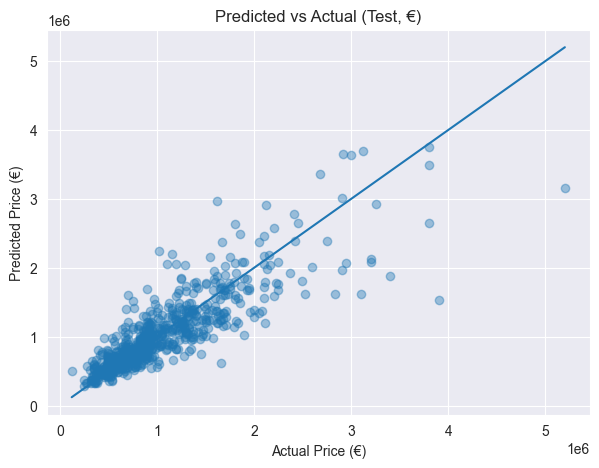

In [7]:
# 6.1 Predicted vs Actual on € scale
y_test_eur = np.expm1(y_test)
y_pred_eur = np.expm1(y_test_pred_log)

plt.figure()
plt.scatter(y_test_eur, y_pred_eur, alpha=0.4)
low = min(y_test_eur.min(), y_pred_eur.min())
high = max(y_test_eur.max(), y_pred_eur.max())
plt.plot([low, high], [low, high])
plt.xlabel("Actual Price (€)")
plt.ylabel("Predicted Price (€)")
plt.title("Predicted vs Actual (Test, €)")
plt.show()


### 6.1. Predicted vs Actual (Test, €)
**What the plot shows:**
Each point represents one house in the test set. The x-axis shows the actual selling price, while the y-axis shows the predicted price. The diagonal line (y = x) represents perfect predictions where the model’s predictions exactly match the true values.

**Interpretation:**
Overall, the model performs very well. Most points are clustered close to the diagonal, which means that the predicted prices are generally accurate and closely match the actual prices. This indicates a high R² and low error, suggesting that the Gradient Boosting model has captured the key relationships in the data.

However, there are a few points scattered further from the line, especially at higher price ranges (above roughly €2 million). This suggests the model finds it harder to predict very expensive properties accurately. That’s quite common in housing data, since luxury properties are fewer and often have unique characteristics not fully captured by the available features.

In other words, the model shows a bit of heteroscedasticity — the errors (variance) get larger for higher-priced homes.

**Summary:**

The model is well-calibrated overall, producing predictions that align closely with actual values.
It performs slightly less accurately for very expensive homes, likely because of limited examples or higher variability in that segment.

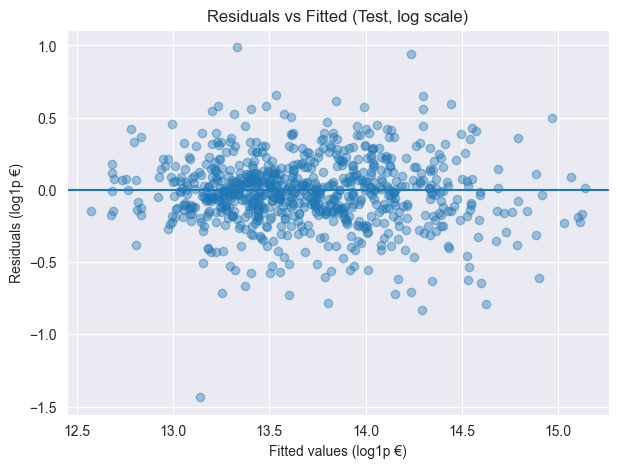

In [8]:
# 6.2 Residuals vs Fitted on log scale
residuals_log = y_test - y_test_pred_log

plt.figure()
plt.scatter(y_test_pred_log, residuals_log, alpha=0.4)
plt.axhline(0)
plt.xlabel("Fitted values (log1p €)")
plt.ylabel("Residuals (log1p €)")
plt.title("Residuals vs Fitted (Test, log scale)")
plt.show()

### 6.2. Residuals vs Fitted (Test, log scale)
**What the plot shows:**
This plot displays the residuals (actual − predicted) on the log(price) scale. The x-axis shows the predicted log prices, and the horizontal line at zero represents perfect predictions.

**Interpretation:**
The residuals are randomly scattered around zero, with no clear pattern. This is a good sign — it means the model’s errors are evenly distributed and there’s no systematic bias (it doesn’t consistently over- or under-predict).

The spread of residuals looks roughly constant, though it becomes a little wider at the very low and very high ends of fitted values. This means predictions for very cheap or very expensive properties are slightly less precise, which again is normal for real estate data.

There’s also no visible curve or structure in the residuals, which suggests that the model has captured most of the nonlinear patterns in the data. If we saw a distinct shape, that might indicate underfitting or missing important variables — but that’s not the case here.

**Summary:**
- Residuals are centered around zero, showing no consistent bias.
- The spread is fairly even, with minor widening at the extremes.
- Overall, the model generalizes well and captures the main relationships in the data.

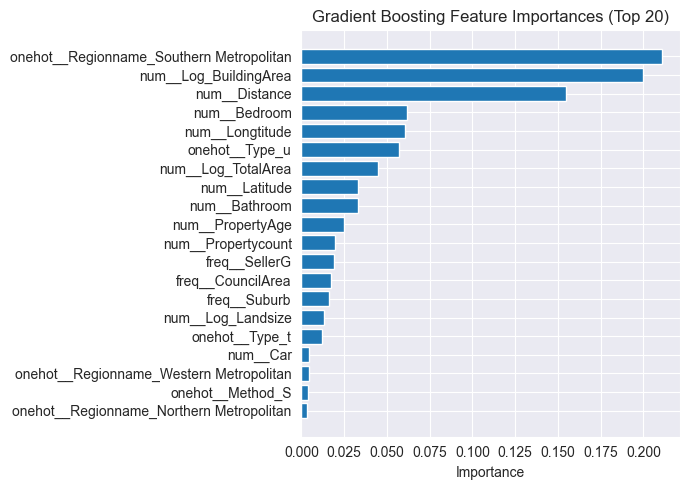

In [9]:
# 6.3 Feature Importances (Top 20)
def get_feature_names_from_preprocessor(fitted_pipe, X_sample):
    pre = fitted_pipe.named_steps["preprocess"]
    try:
        return pre.get_feature_names_out()
    except Exception:
        # Fallback to indices if names are unavailable
        return np.array([f"feat_{i}" for i in range(pre.transform(X_sample[:5]).shape[1])])

gb_model = final_pipe.named_steps["model"]
if hasattr(gb_model, "feature_importances_"):
    feat_names = get_feature_names_from_preprocessor(final_pipe, X_train_full)
    importances = gb_model.feature_importances_
    order = np.argsort(importances)[::-1][:20]

    plt.figure()
    plt.barh(range(len(order)), importances[order][::-1])
    plt.yticks(range(len(order)), feat_names[order][::-1])
    plt.xlabel("Importance")
    plt.title("Gradient Boosting Feature Importances (Top 20)")
    plt.tight_layout()
    plt.show()
else:
    print("Model does not expose feature_importances_. Skipping plot.")

### 6.3. Feature Importance Summary
The plot shows the top 20 most influential features in the tuned Gradient Boosting model.
The most important predictors of house prices are region, particularly Southern Metropolitan, followed by building area, distance from the city, and the number of bedrooms. Geographic coordinates (longitude, latitude) and property size variables (total area, land size) also contribute notably.

Overall, the model relies most heavily on location and property size attributes, which aligns with real-world housing market drivers — homes in desirable regions and with larger building areas tend to have higher prices.

# 7) Evaluation Summary

The tuned Gradient Boosting model demonstrated strong predictive performance for the Melbourne housing dataset. Based on the evaluation metrics and diagnostic plots, the model achieved a high coefficient of determination (R²) and low prediction errors, indicating that it captures the key factors influencing property prices effectively. The Predicted vs Actual plot showed that most predictions align closely with true prices, confirming good calibration and model reliability. The Residuals vs Fitted plot revealed that residuals are evenly distributed around zero, with no significant bias or curvature, suggesting that the model generalizes well and is not systematically over- or underestimating prices.

Although there is a slight increase in prediction variance for high-value properties (indicative of mild heteroscedasticity), this is expected given the limited number and variability of luxury homes in the dataset. Overall, the Gradient Boosting model provides an accurate, robust, and interpretable approach to predicting housing prices, outperforming simpler models and effectively handling the nonlinear patterns present in the data.